# Implementação prática dos usos da Média em Python.

* Criação do dataset: Vamos criar um dataset sintético simulando a base de dados de avaliações e características de produtos de um e-commerce. Assim poderemos visualizar as aplicações práticas dos conceitos estatísticos e probabilísticos:

In [2]:
import numpy as np
import pandas as pd

np.random.seed(42)

data = {
    "Produto_id": range(101, 111),
    "Categoria": [
        "Eletrônicos", "Eletrônicos", "Roupas",
        "Eletrônicos", "Roupas", "Livros",
        "Livros", "Eletrônicos", "Roupas", "Livros"
    ],
    "preco_brl": [2500, 150, 80, 1200, 120, 45, 60, 3500, 200, 30],
    "nota_avaliacao": [4.8, 3.5, 4.2, 4.9, 2.1, 4.5, 4.7, 4.0, 3.8, 4.9],
    "num_avaliacoes": [1200, 45, 300, 850, 12, 500, 230, 15, 80, 950],
    "peso_relevancia_categoria": [0.4, 0.4, 0.3, 0.4, 0.3, 0.3, 0.3, 0.4, 0.3, 0.3]
}

df = pd.DataFrame(data)
display(df)

,Produto_id,Categoria,preco_brl,nota_avaliacao,num_avaliacoes,peso_relevancia_categoria
0,101,Eletrônicos,2500,4.8,1200,0.4
1,102,Eletrônicos,150,3.5,45,0.4
2,103,Roupas,80,4.2,300,0.3
3,104,Eletrônicos,1200,4.9,850,0.4
4,105,Roupas,120,2.1,12,0.3
5,106,Livros,45,4.5,500,0.3
6,107,Livros,60,4.7,230,0.3
7,108,Eletrônicos,3500,4.0,15,0.4
8,109,Roupas,200,3.8,80,0.3
9,110,Livros,30,4.9,950,0.3


1. Média Aritmética: A média aritmética simples divide a soma dos valores pela quantidade total de elementos.

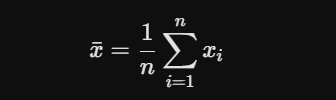

* Aplicações da Média Aritmética dentro da Análise e Ciência de Dados, ML e IA:

* Obs: Esses são apenas alguns exemplos, mais adiante veremos mais aplicações onde a Média, seja ela aritmética ou ponderada, se faz presente.

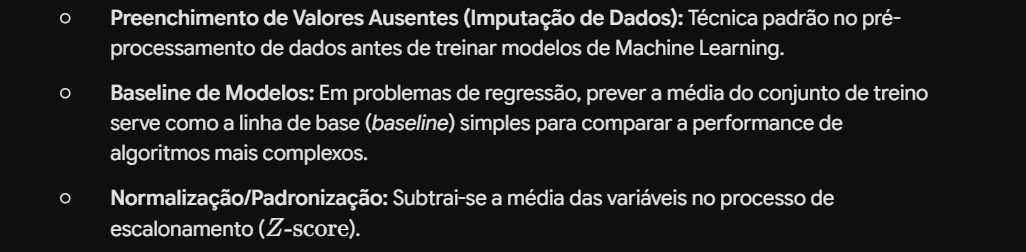

* Exemplo em python:

In [4]:
# Média do preço dos produtos:
media_preco = df["preco_brl"].mean()
print(f"Preço médio geral: R${media_preco:.2f}")

# Média do preço por categoria (Agrupamento e Sumarização):
media_preco_categoria = df.groupby("Categoria")["preco_brl"].mean()
print("\nPreço médio por categoria:")
print(media_preco_categoria)

Preço médio geral: R$788.50

Preço médio por categoria:
Categoria
Eletrônicos    1837.500000
Livros           45.000000
Roupas          133.333333
Name: preco_brl, dtype: float64


2. Média Ponderada: A média ponderada atribui pesos (wi) a cada elemento (xi), onde valores com maior peso influenciam mais o resultado final.

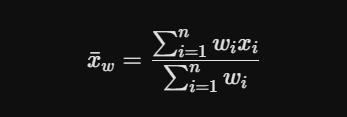

* Aplicações da Média Ponderada dentro do contexto de IA e Ciência de Dados:

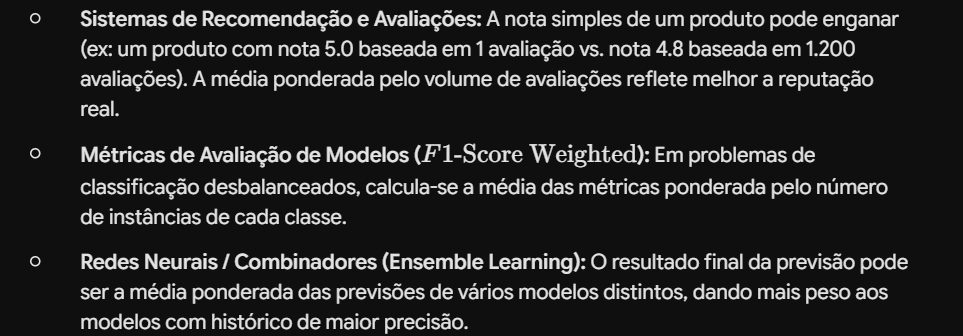

* Aplicação em Python:

In [5]:
# Cenário: Calcular a nota média real dos produtos ponderada pelo volume de avaliações que cada um recebeu.

# Média simples da nota (pode ser enganosa):

media_simples_nota = df["nota_avaliacao"].mean()

# Média ponderada da nota usando o número de avaliações como peso:

media_ponderada_nota = np.average(df["nota_avaliacao"], weights=df["num_avaliacoes"])

print(f"Média simples das notas: {media_simples_nota:.2f}")
print(f"Média ponderada das notas: {media_ponderada_nota:.2f}")

Média simples das notas: 4.14
Média ponderada das notas: 4.71


* Cenário: Criar um Score Geral de Relevância combinando preço e nota ponderados:

In [7]:
# Exemplo de criação de uma feature combinada no dataset
# Peso 0.7 para a nota do produto e 0.3 para o volume de avaliações (normalizados)

nota_norm = df["nota_avaliacao"] / 5
vol_norm = df["num_avaliacoes"] / df["num_avaliacoes"].max()

df["score_relevancia"] = np.average(
    [nota_norm, vol_norm], weights=[0.7, 0.3], axis=0
)

display(df[['Produto_id', 'nota_avaliacao', 'num_avaliacoes', 'score_relevancia']])

,Produto_id,nota_avaliacao,num_avaliacoes,score_relevancia
0,101,4.8,1200,0.97200
1,102,3.5,45,0.50125
2,103,4.2,300,0.66300
3,104,4.9,850,0.89850
4,105,2.1,12,0.29700
5,106,4.5,500,0.75500
6,107,4.7,230,0.71550
7,108,4.0,15,0.56375
8,109,3.8,80,0.55200
9,110,4.9,950,0.92350


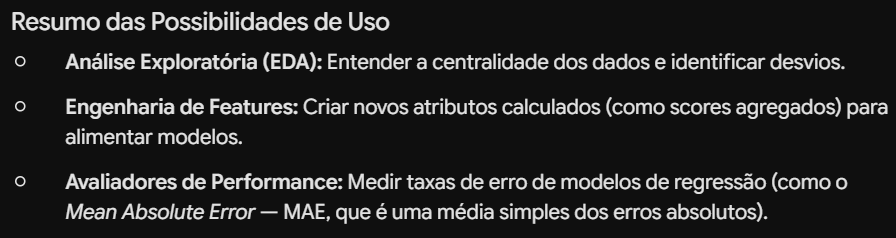